# JEV and Gemma 4: probability and calibration comparison

Gemma uses reasoning disabled and reports the log probabilities of the exact `0` and `1` tokens at the first output position. Its raw positive score is `exp(logprob_1) / (exp(logprob_0) + exp(logprob_1))`. Both alternatives must be present; missing alternatives are never treated as zero. Sampling uses temperature 1 and top-p 1; classification is computed from the score, not from the sampled token. A one-token response ending with `length` is expected in this scoring experiment.

This is a new **label-only prompt**, not the earlier JSON label/source/reason classifier. The include-news task definition is retained. Darkbloom is pinned. All 1,059 Gemma requests reported zero reasoning tokens and both label probabilities.

JEV uses its native positive-class probability. Its 559 saved test predictions were reused and input hashes verified; the validation run resolved to the same model version.

## Data and calibration

A reproducible random sample of 500 emails (67 positive) was selected from the training file, after removing whitespace-normalized duplicates, contradictory duplicate groups, and any exact normalized overlap with test emails. This sample serves only as validation for probability calibration. The test set retains all 559 original rows (554 unique texts). Near-duplicate articles and email threads have not been deduplicated; the benchmark has also been inspected in prior experiments, so fresh data is still needed for a confirmatory comparison.

For each model, a sigmoid is fit to log odds using the validation labels, with a fixed L2 slope penalty of 1. Numerical clipping at 1e-12 handles probabilities of exactly 0 or 1. No model weights are trained and no test labels are used to fit the calibrator or select the F1 threshold. A score is the probability of **class 1**; confidence in the selected class is `max(p, 1-p)` when using threshold 0.5.

This notebook runs offline. New requests are collected separately with `python -m scripts.confidence_comparison --collect`; NumPy is required for evaluation.


In [1]:
import json
import sys
from pathlib import Path
from IPython.display import SVG, display
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'scripts/evaluate_confidence.py').exists())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from scripts.evaluate_confidence import evaluate
report = evaluate()
ARTIFACTS = REPO/'data/confidence_comparison'
print('Calibration fitted on 500 validation emails; evaluated on 559 test emails.')


Calibration fitted on 500 validation emails; evaluated on 559 test emails.


## Probability quality and classification at threshold 0.5

Brier score is mean squared probability error; log loss penalizes confident mistakes. Lower is better for both. Average precision summarizes ranking across thresholds; higher is better. Calibration changes the meaning of a 0.5 cutoff, so its precision/recall tradeoff can move even though score ordering remains unchanged.


In [2]:
print(f"{'Model / score':<24} {'Brier':>8} {'Log loss':>9} {'Avg prec':>9} {'Precision':>10} {'Recall':>8} {'F1':>8}")
for name, entry in report['models'].items():
    for mode in ('raw', 'calibrated'):
        s = entry[mode]
        print(f"{name+' '+mode:<24} {s['brier']:>8.4f} {s['log_loss']:>9.4f} {s['average_precision']:>9.3f} {s['precision']:>10.3f} {s['recall']:>8.3f} {s['f1']:>8.3f}")


Model / score               Brier  Log loss  Avg prec  Precision   Recall       F1
jev raw                    0.0606    0.2023     0.772      0.680    0.699    0.689
jev calibrated             0.0570    0.1943     0.772      0.746    0.644    0.691
gemma4 raw                 0.1348    1.3533     0.735      0.475    0.918    0.626
gemma4 calibrated          0.0624    0.2009     0.735      0.622    0.767    0.687


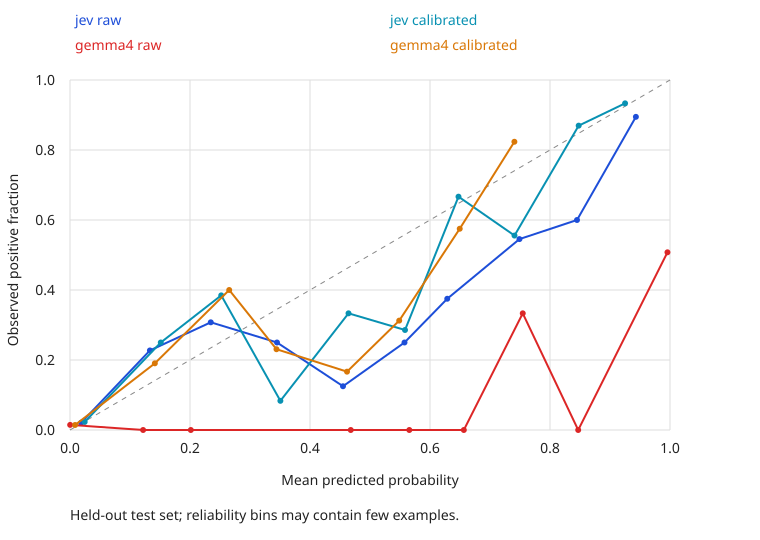

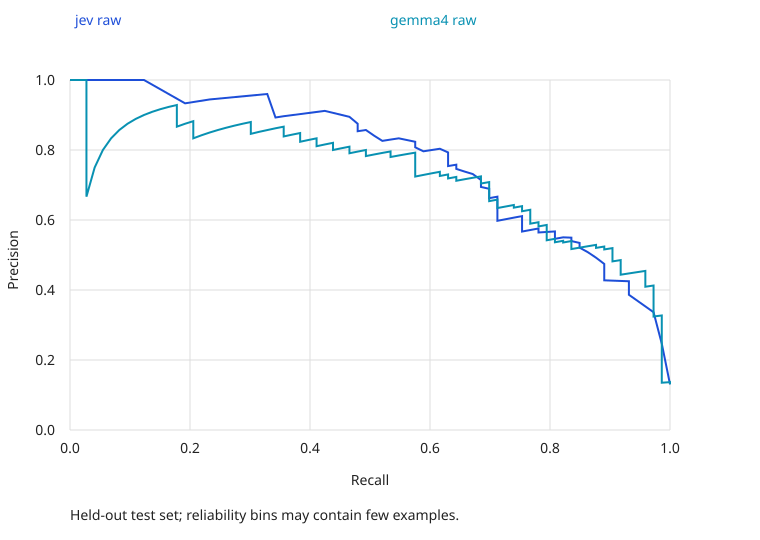

In [3]:
display(SVG(filename=str(ARTIFACTS/'calibration.svg')))
display(SVG(filename=str(ARTIFACTS/'precision_recall.svg')))


## Validation-selected thresholds

These thresholds maximize validation F1, with precision and then the higher threshold breaking ties. They were fixed using validation scores before computing the test metrics below. A different review objective (for example high recall) needs its own validation-based threshold choice.


In [4]:
for name, entry in report['models'].items():
    print(name, json.dumps(entry['validation_selected_threshold'], indent=2))


jev {
  "threshold": 0.3484254389150936,
  "tp": 52,
  "fp": 30,
  "fn": 21,
  "tn": 456,
  "precision": 0.6341463414634146,
  "recall": 0.7123287671232876,
  "f1": 0.6709677419354839
}
gemma4 {
  "threshold": 0.4784968041469737,
  "tp": 57,
  "fp": 39,
  "fn": 16,
  "tn": 447,
  "precision": 0.59375,
  "recall": 0.7808219178082192,
  "f1": 0.6745562130177515
}


## Costs and saved outputs

Costs below come from the saved successful requests. JEV's test cost is historical and was not charged again. A few exploratory Gemma pilot requests are additional to these totals. Calibration itself makes no API calls. Per-email raw and calibrated scores are saved as `data/confidence_comparison/{jev,gemma4}_test_probabilities.csv`; fitted parameters and metrics are in `evaluation.json`.


In [5]:
for name, entry in report['models'].items():
    print(name, 'validation cost:', round(entry['validation_cost_usd'], 6), 'test cost:', round(entry['test_cost_usd'], 6))


jev validation cost: 0.016158 test cost: 0.018535
gemma4 validation cost: 0.011472 test cost: 0.01358


## Score a new email

Use the helper below from Python with `model='jev'` or `model='gemma4'`. This makes a new API call and reads the saved validation calibrator. It returns raw probability, calibrated positive probability, predicted class, and confidence in that class. The API key is read from the environment or the local Git-ignored `.env`.

```python
from scripts.confidence_comparison import predict_with_confidence
result = predict_with_confidence(email_text, model='gemma4')
# Or: result = predict_with_confidence(email_text, model='jev')
```

These probabilities are calibrated to this curated dataset. A different prevalence or email source may require new calibration data. The reliability plots have small bins and no uncertainty intervals; they are descriptive.
